# HW5 전처리 재현 + 질문 셋
김성준 · 22011734

원본 주문 데이터에서 중복과 수량 오류를 처리한 뒤 배송기간, 만족도별 반품 비율, 카테고리 매출을 분석한다. 원본은 그대로 보존한다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform
from IPython.display import display

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

Matplotlib is building the font cache; this may take a moment.


## ① 읽고 날짜 세 칸을 날짜로 변환
입력 파일은 노트북과 같은 폴더의 `sales_data.csv`다. 결측치는 임의의 값으로 채우지 않고 각 분석에 필요한 칸이 없을 때만 제외한다.

In [2]:
df = pd.read_csv("sales_data.csv")
for col in ["order_date", "shipping_date", "delivery_date"]:
    df[col] = pd.to_datetime(df[col])
print("원본 크기:", df.shape)
display(df.head())
display(df[["customer_age", "satisfaction", "delivery_date"]].isna().sum().rename("결측 수"))

원본 크기: (1030, 14)


,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


customer_age     51
satisfaction     30
delivery_date     5
Name: 결측 수, dtype: int64

## ② 중복 행 제거
14개 칸이 모두 같은 행은 중복으로 보고 첫 번째 행만 남긴다. 결측치가 있는 행 전체를 삭제하지 않는다.

In [3]:
before = len(df)
df = df.drop_duplicates().copy()
print(before, "->", len(df))
print("제거한 중복 행:", before - len(df))

1030 -> 1004
제거한 중복 행: 26


## ③ 수량 복원
수량이 100을 넘는 행을 확인한다. 해당 행은 금액과 수량×단가가 어긋나고 금액÷단가가 정수이므로, 수업의 주문 수량 규칙에 따라 수량만 복원한다.

In [4]:
bad = df["quantity"] > 100
ratio = df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]
print("복원값이 정수인가:", ((ratio - ratio.round()).abs() < 1e-8).all())
df.loc[bad, "quantity"] = ratio.round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄:", bad.sum(), " 수량 최대:", df["quantity"].max(), " 총액 안 맞는 줄:", (diff > 1).sum())

복원값이 정수인가: True
고친 줄: 22  수량 최대: 99  총액 안 맞는 줄: 0


## ④ 날짜 오류 표시 및 정리 파일 저장
도착일이 배송일보다 빠른 행은 어느 날짜가 틀렸는지 알 수 없어 `date_error`로 표시한다. 날짜를 고치거나 주문을 삭제하지 않고, 배송기간 분석에서만 제외한다.

In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df.to_csv("sales_clean.csv", index=False)
print("날짜 오류:", df["date_error"].sum())
print("저장한 크기:", df.shape)
display(df["date_error"].value_counts())

날짜 오류: 147
저장한 크기: (1004, 15)


date_error
False    857
True     147
Name: count, dtype: int64

## ⑤ 배송기간은 보통 며칠인가?
날짜 순서 오류를 제외하고 도착일−배송일을 계산한다. 날짜가 없는 행은 기간을 계산할 수 없으므로 제외하며, 우선 긴 기간을 포함한 분포를 확인한다.

전체: 1004  날짜 오류: 147  도착일 결측: 5  기간 계산 가능: 852
평균: 22.05일, 중앙값: 2일


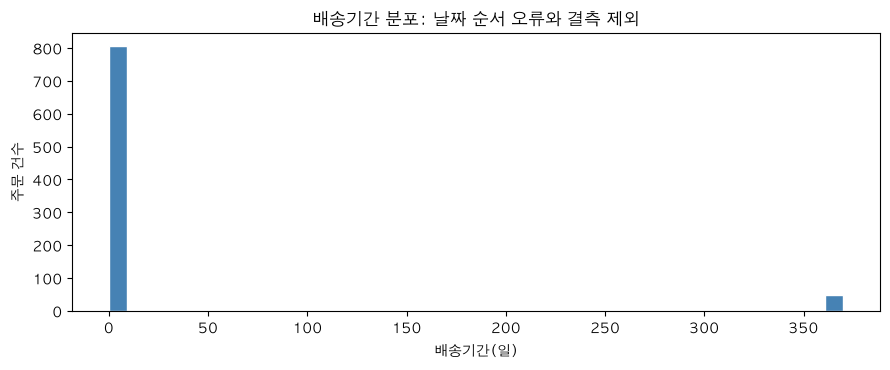

300일 초과: 47 건


364.0     6
365.0    10
366.0     6
367.0     9
368.0     8
369.0     5
370.0     3
Name: 건수, dtype: int64

,shipping_date,delivery_date,status
11,2023-01-15,2024-01-15,배송완료
20,2023-01-23,2024-01-27,배송완료
29,2023-02-03,2024-02-03,배송완료
41,2023-02-14,2024-02-17,배송완료
68,2023-03-14,2024-03-12,배송완료


In [6]:
days = (df.loc[~df["date_error"], "delivery_date"]
        - df.loc[~df["date_error"], "shipping_date"]).dt.days.dropna()
print("전체:", len(df), " 날짜 오류:", df["date_error"].sum(),
      " 도착일 결측:", df["delivery_date"].isna().sum(), " 기간 계산 가능:", len(days))
print(f"평균: {days.mean():.2f}일, 중앙값: {days.median():.0f}일")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(days, bins=40, color="steelblue", edgecolor="white")
ax.set(title="배송기간 분포: 날짜 순서 오류와 결측 제외", xlabel="배송기간(일)", ylabel="주문 건수")
plt.tight_layout()
plt.show()
long_days = days[days > 300]
print("300일 초과:", len(long_days), "건")
display(long_days.value_counts().sort_index().rename("건수"))
display(df.loc[long_days.index, ["shipping_date", "delivery_date", "status"]].head())

오른쪽 끝 47건은 364~370일이고 나머지는 0~5일로 떨어져 있다. 연도 입력 오류가 의심되지만 실제 지연인지 확인할 자료가 없어 1년을 빼서 고치지 않는다. 이 47건은 **일반적인 배송기간 요약에서만 제외**하고 원본 및 `sales_clean.csv`에는 유지한다. 300일은 두 덩어리를 구분하기 위한 이번 데이터의 기준이며 일반적인 배송 지연 기준은 아니다.

별도 분리 전: 852건, 평균 22.05일, 중앙값 2일
47건 분리 후: 805건, 평균 1.93일, 중앙값 2일


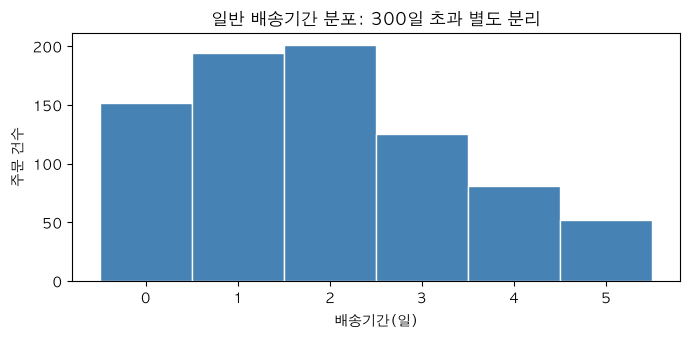

In [7]:
usual_days = days[days <= 300]
print(f"별도 분리 전: {len(days)}건, 평균 {days.mean():.2f}일, 중앙값 {days.median():.0f}일")
print(f"47건 분리 후: {len(usual_days)}건, 평균 {usual_days.mean():.2f}일, 중앙값 {usual_days.median():.0f}일")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(usual_days, bins=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], color="steelblue", edgecolor="white")
ax.set(title="일반 배송기간 분포: 300일 초과 별도 분리", xlabel="배송기간(일)", ylabel="주문 건수", xticks=range(6))
plt.tight_layout()
plt.show()

**답**  
날짜 오류 147건과 도착일 결측 5건을 제외한 852건은 평균 22.05일, 중앙값 2일이며, 364~370일인 47건이 평균을 끌어올렸다.  
47건은 연도 오류 여부를 확정할 수 없어 날짜를 보존하고 기간 요약에서만 제외했다. 남은 805건은 평균 1.93일, 중앙값 2일로 보통 약 2일이다.

## ⑥ 만족도가 낮을수록 반품이 많은가?
만족도별 전체 주문 중 `status == "반품"`인 비율을 비교한다. 만족도 결측 30건만 이 분석에서 제외한다.

분석 주문: 974  만족도 결측 제외: 30


,주문건수,반품건수,반품비율
satisfaction,,,
1.0,224,17,7.59
2.0,184,22,11.96
3.0,192,15,7.81
4.0,172,15,8.72
5.0,202,14,6.93


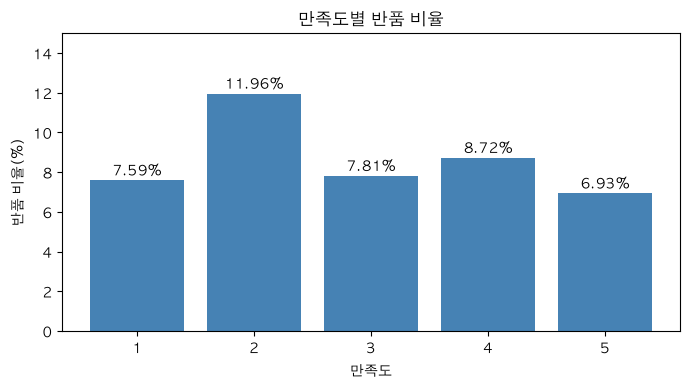

In [8]:
returns = df.assign(returned=df["status"].eq("반품")).groupby("satisfaction").agg(
    주문건수=("returned", "size"), 반품건수=("returned", "sum"), 반품비율=("returned", "mean")
)
returns["반품비율"] *= 100
print("분석 주문:", returns["주문건수"].sum(), " 만족도 결측 제외:", df["satisfaction"].isna().sum())
display(returns.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(returns.index, returns["반품비율"], color="steelblue")
for score, rate in returns["반품비율"].items():
    ax.text(score, rate + 0.25, f"{rate:.2f}%", ha="center")
ax.set(title="만족도별 반품 비율", xlabel="만족도", ylabel="반품 비율(%)", xticks=range(1, 6), ylim=(0, 15))
plt.tight_layout()
plt.show()

**답**  
만족도 1~5점의 반품 비율은 각각 7.59%, 11.96%, 7.81%, 8.72%, 6.93%로, 낮을수록 반품이 많다는 일관된 경향은 보이지 않는다.  
2점이 가장 높고 1점은 4점보다 낮다. 만족도 결측 30건을 제외한 974건의 기술통계이며, 만족도가 반품의 원인이라고 판단할 수는 없다.

## ⑦ 카테고리 매출 1위의 이유는 건수·단가·수량 중 무엇인가?
카테고리별 주문 건수, 매출 합계, 평균 단가와 평균 수량을 비교한다. 매출은 수업과 같이 전체 주문의 `total_sales` 합계이며 반품 금액을 차감한 순매출은 아니다.

In [9]:
summary = df.groupby("category").agg(
    주문건수=("total_sales", "size"), 매출합계=("total_sales", "sum"),
    평균단가=("unit_price", "mean"), 평균수량=("quantity", "mean")
).sort_values("매출합계", ascending=False)
summary["매출합계"] /= 1e8
summary = summary.rename(columns={"매출합계": "매출합계(억원)", "평균단가": "평균단가(원)"})
display(summary.round(2))

,주문건수,매출합계(억원),평균단가(원),평균수량
category,,,,
가구,213,28.43,257322.91,51.04
식품,210,25.13,255232.93,47.31
전자제품,207,24.72,249651.61,47.96
도서,204,24.53,238500.64,49.50
의류,170,21.82,249447.16,51.61


**답**  
가구가 매출 28.43억원으로 1위이며, 주문 213건과 평균 단가 257,322.91원도 1위다. 평균 수량 51.04개는 의류 51.61개보다 작아 2위다.  
매출 2위 식품(25.13억원)은 210건·평균 단가 255,232.93원·평균 수량 47.31개로, 가구는 세 항목이 모두 높고 특히 평균 수량 차이가 크다. 다만 이 집계만으로 한 항목의 인과적 기여를 확정할 수는 없다.